In [2]:
import pandas as pd
import numpy as np

In [3]:
import pandas as pd

df = pd.read_csv(r"C:\Users\SANJAY\Documents\data\Global_Superstore2.csv", encoding="latin1")
df.head().transpose()

,0,1,2,3,4
Row ID,32298,26341,25330,13524,47221
Order ID,CA-2012-124891,IN-2013-77878,IN-2013-71249,ES-2013-1579342,SG-2013-4320
Order Date,31-07-2012,05-02-2013,17-10-2013,28-01-2013,05-11-2013
Ship Date,31-07-2012,07-02-2013,18-10-2013,30-01-2013,06-11-2013
Ship Mode,Same Day,Second Class,First Class,First Class,Same Day
Customer ID,RH-19495,JR-16210,CR-12730,KM-16375,RH-9495
Customer Name,Rick Hansen,Justin Ritter,Craig Reiter,Katherine Murray,Rick Hansen
Segment,Consumer,Corporate,Consumer,Home Office,Consumer
City,New York City,Wollongong,Brisbane,Berlin,Dakar
State,New York,New South Wales,Queensland,Berlin,Dakar


In [4]:
df.shape

(51290, 24)

In [5]:
df.tail().transpose()

,51285,51286,51287,51288,51289
Row ID,29002,35398,40470,9596,6147
Order ID,IN-2014-62366,US-2014-102288,US-2013-155768,MX-2012-140767,MX-2012-134460
Order Date,19-06-2014,20-06-2014,02-12-2013,18-02-2012,22-05-2012
Ship Date,19-06-2014,24-06-2014,02-12-2013,22-02-2012,26-05-2012
Ship Mode,Same Day,Standard Class,Same Day,Standard Class,Second Class
Customer ID,KE-16420,ZC-21910,LB-16795,RB-19795,MC-18100
Customer Name,Katrina Edelman,Zuschuss Carroll,Laurel Beltran,Ross Baird,Mick Crebagga
Segment,Corporate,Consumer,Home Office,Home Office,Consumer
City,Kure,Houston,Oxnard,Valinhos,Tipitapa
State,Hiroshima,Texas,California,São Paulo,Managua


In [24]:
df.sample(5).transpose()

,30847,17805,25614,46173,6102
Row_ID,2417,18441,36422,18223,14524
Order_ID,MX-2014-105445,ES-2013-1521931,CA-2011-160766,ES-2013-2371724,IT-2014-4046179
Order_Date,2014-07-11 00:00:00,2013-06-07 00:00:00,2011-09-14 00:00:00,2013-08-24 00:00:00,2014-12-27 00:00:00
Ship_Date,2014-07-15 00:00:00,2013-06-10 00:00:00,2011-09-14 00:00:00,2013-08-27 00:00:00,2014-12-30 00:00:00
Ship_Mode,Standard Class,Second Class,Same Day,Second Class,Second Class
Customer_ID,BS-11800,SJ-20125,DM-13015,DW-13480,JF-15490
Customer_Name,Bryan Spruell,Sanjit Jacobs,Darrin Martin,Dianna Wilson,Jeremy Farry
Segment,Home Office,Home Office,Consumer,Home Office,Consumer
City,Monterrey,Marseille,New York City,Solingen,Stockholm
State,Nuevo León,Provence-Alpes-Côte d'Azur,New York,North Rhine-Westphalia,Stockholm


# Inspect

In [7]:
print(df.shape)
df.info()
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

(51290, 24)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          51290 non-null  int64  
 1   Order ID        51290 non-null  object 
 2   Order Date      51290 non-null  object 
 3   Ship Date       51290 non-null  object 
 4   Ship Mode       51290 non-null  object 
 5   Customer ID     51290 non-null  object 
 6   Customer Name   51290 non-null  object 
 7   Segment         51290 non-null  object 
 8   City            51290 non-null  object 
 9   State           51290 non-null  object 
 10  Country         51290 non-null  object 
 11  Postal Code     9994 non-null   float64
 12  Market          51290 non-null  object 
 13  Region          51290 non-null  object 
 14  Product ID      51290 non-null  object 
 15  Category        51290 non-null  object 
 16  Sub-Category    51290 non-null  object 
 17  Product Name    512

# Remove duplicates and fix column names

In [8]:
df = df.drop_duplicates()
df.columns = df.columns.str.strip().str.replace(" ", "_").str.replace("-", "_")
df.columns

Index(['Row_ID', 'Order_ID', 'Order_Date', 'Ship_Date', 'Ship_Mode',
       'Customer_ID', 'Customer_Name', 'Segment', 'City', 'State', 'Country',
       'Postal_Code', 'Market', 'Region', 'Product_ID', 'Category',
       'Sub_Category', 'Product_Name', 'Sales', 'Quantity', 'Discount',
       'Profit', 'Shipping_Cost', 'Order_Priority'],
      dtype='object')

# Convert dates (dd-mm-yyyy)

In [9]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"], dayfirst=True, errors="coerce")
df["Ship_Date"] = pd.to_datetime(df["Ship_Date"], dayfirst=True, errors="coerce")
print(df[["Order_Date", "Ship_Date"]].dtypes)
print(df[["Order_Date", "Ship_Date"]].isnull().sum())

Order_Date    datetime64[ns]
Ship_Date     datetime64[ns]
dtype: object
Order_Date    0
Ship_Date     0
dtype: int64


# Drop Postal Code and trim text

In [10]:
df = df.drop(columns=["Postal_Code"])

for c in df.select_dtypes("object"):
    df[c] = df[c].str.strip()

# Add new columns

In [11]:
df["Year"] = df["Order_Date"].dt.year
df["Month_Num"] = df["Order_Date"].dt.month
df["Month"] = df["Order_Date"].dt.month_name()
df["Ship_Days"] = (df["Ship_Date"] - df["Order_Date"]).dt.days
df["Profit_Margin"] = np.where(df["Sales"] != 0, df["Profit"] / df["Sales"] * 100, 0)
df["Loss_Flag"] = df["Profit"] < 0

df["Discount_Band"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0, 0.1, 0.2, 0.3, 1],
    labels=["0%", "1-10%", "11-20%", "21-30%", "30%+"]
)
df.head()

,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,City,State,...,Profit,Shipping_Cost,Order_Priority,Year,Month_Num,Month,Ship_Days,Profit_Margin,Loss_Flag,Discount_Band
0,32298,CA-2012-124891,2012-07-31,2012-07-31,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,762.1845,933.57,Critical,2012,7,July,0,33.000000,False,0%
1,26341,IN-2013-77878,2013-02-05,2013-02-07,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,-288.7650,923.63,Critical,2013,2,February,2,-7.784693,True,1-10%
2,25330,IN-2013-71249,2013-10-17,2013-10-18,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,919.9710,915.49,Medium,2013,10,October,1,17.776630,False,1-10%
3,13524,ES-2013-1579342,2013-01-28,2013-01-30,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,-96.5400,910.16,Medium,2013,1,January,2,-3.337586,True,1-10%
4,47221,SG-2013-4320,2013-11-05,2013-11-06,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,311.5200,903.04,Critical,2013,11,November,1,10.996272,False,0%


# Outlier check on Profit (IQR) 

Profit outliers: 9755


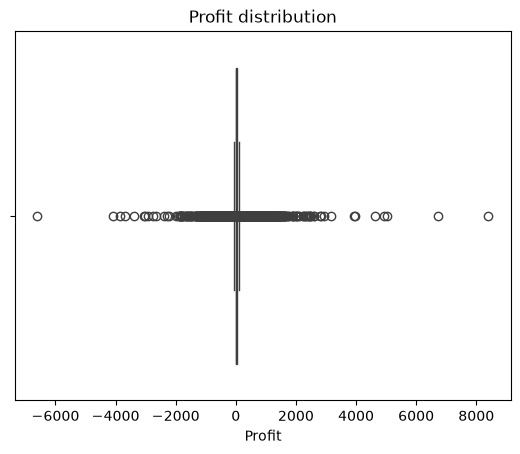

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
q1, q3 = df["Profit"].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df[(df["Profit"] < q1 - 1.5 * iqr) | (df["Profit"] > q3 + 1.5 * iqr)]
print("Profit outliers:", len(outliers))

sns.boxplot(x=df["Profit"])
plt.title("Profit distribution")
plt.show()

# Summary statistics

In [15]:
df[["Sales", "Quantity", "Discount", "Profit", "Shipping_Cost"]].describe()

,Sales,Quantity,Discount,Profit,Shipping_Cost
count,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000
mean,246.490581,3.476545,0.142908,28.610982,26.375915
std,487.565361,2.278766,0.212280,174.340972,57.296804
min,0.444000,1.000000,0.000000,-6599.978000,0.000000
25%,30.758625,2.000000,0.000000,0.000000,2.610000
50%,85.053000,3.000000,0.000000,9.240000,7.790000
75%,251.053200,5.000000,0.200000,36.810000,24.450000
max,22638.480000,14.000000,0.850000,8399.976000,933.570000


# Sales and profit by year

          Sales    Profit  Margin_%
Year                               
2011  2259450.9  248940.8      11.0
2012  2677438.7  307415.3      11.5
2013  3405746.4  406935.2      11.9
2014  4299865.9  504166.0      11.7


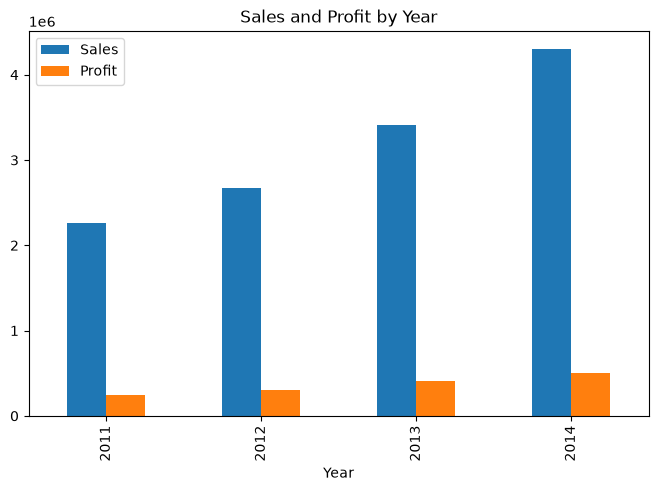

In [16]:
yearly = df.groupby("Year")[["Sales", "Profit"]].sum()
yearly["Margin_%"] = yearly["Profit"] / yearly["Sales"] * 100
print(yearly.round(1))

yearly[["Sales", "Profit"]].plot(kind="bar", figsize=(8, 5), title="Sales and Profit by Year")
plt.show()

# By category and sub-category

                     Sales    Profit  Margin_%
Category                                      
Furniture        4110874.2  285204.7       6.9
Office Supplies  3787070.2  518473.8      13.7
Technology       4744557.5  663778.7      14.0


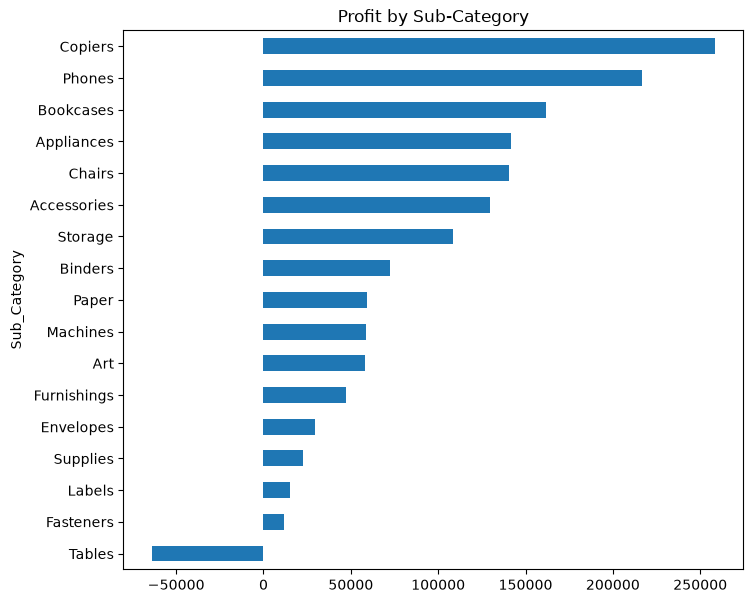

In [17]:
cat = df.groupby("Category")[["Sales", "Profit"]].sum()
cat["Margin_%"] = cat["Profit"] / cat["Sales"] * 100
print(cat.round(1))

sub = df.groupby("Sub_Category")["Profit"].sum().sort_values()
sub.plot(kind="barh", figsize=(8, 7), title="Profit by Sub-Category")
plt.show()

# By market

            Sales    Profit  Margin_%
Market                               
APAC    3585744.1  436000.0      12.2
Africa   783773.2   88871.6      11.3
Canada    66928.2   17817.4      26.6
EMEA     806161.3   43898.0       5.4
EU      2938089.1  372829.7      12.7
LATAM   2164605.2  221643.5      10.2
US      2297200.9  286397.0      12.5


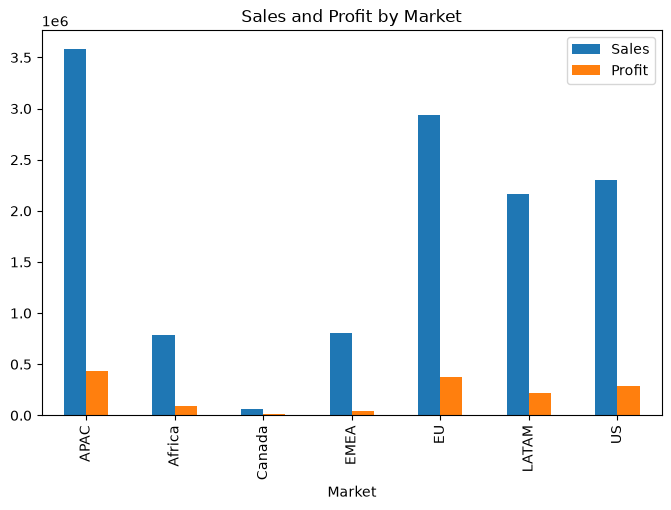

In [18]:
mkt = df.groupby("Market")[["Sales", "Profit"]].sum()
mkt["Margin_%"] = mkt["Profit"] / mkt["Sales"] * 100
print(mkt.round(1))

mkt[["Sales", "Profit"]].plot(kind="bar", figsize=(8, 5), title="Sales and Profit by Market")
plt.show()

# By country (best and worst)

Worst 10:
 Country
Turkey        -98447.0
Nigeria       -80751.0
Netherlands   -41070.0
Honduras      -29482.0
Pakistan      -22447.0
Argentina     -18694.0
Panama        -17723.0
Sweden        -17519.0
Philippines   -16128.0
South Korea   -12793.0
Name: Profit, dtype: float64
Best 10:
 Country
El Salvador        42023.0
Spain              54390.0
Mexico            102818.0
Australia         103907.0
Germany           107323.0
France            109029.0
United Kingdom    111900.0
India             129072.0
China             150683.0
United States     286397.0
Name: Profit, dtype: float64
Loss-making countries: 29 of 147


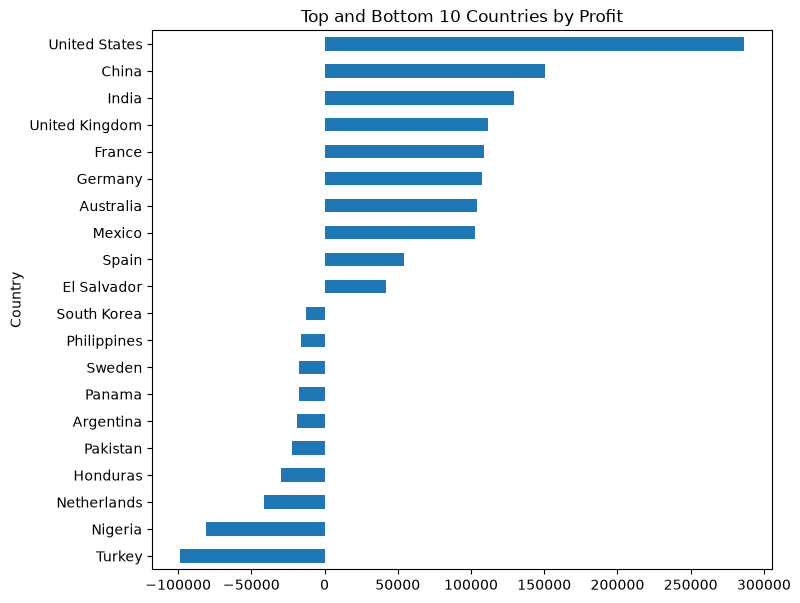

In [19]:
country = df.groupby("Country")["Profit"].sum().sort_values()
print("Worst 10:\n", country.head(10).round(0))
print("Best 10:\n", country.tail(10).round(0))
print("Loss-making countries:", (country < 0).sum(), "of", len(country))

pd.concat([country.head(10), country.tail(10)]).plot(kind="barh", figsize=(8, 7), title="Top and Bottom 10 Countries by Profit")
plt.show()

# Profit by discount band

                   Sales     Profit  Avg_Profit  Margin_%
Discount_Band                                            
0%             6992411.0  1770695.3        61.0      25.3
1-10%          1962618.8   338189.3        72.3      17.2
11-20%         1757261.3   173254.8        27.6       9.9
21-30%          382554.7   -21155.6       -21.9      -5.5
30%+           1547656.1  -793526.5       -76.6     -51.3


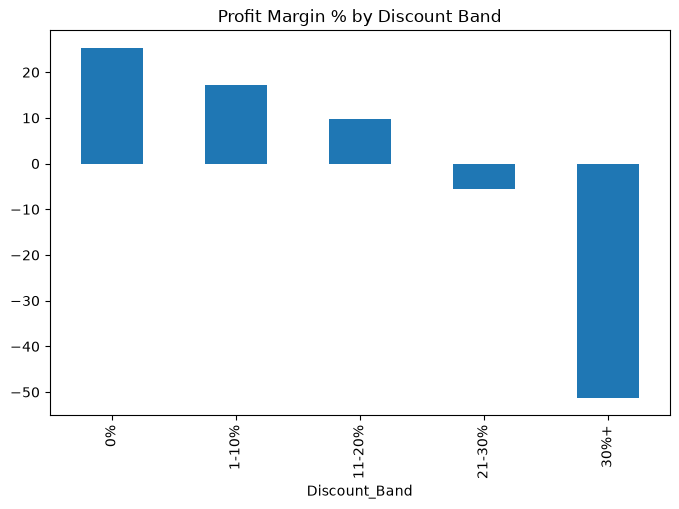

In [20]:
disc = df.groupby("Discount_Band", observed=True).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Avg_Profit=("Profit", "mean")
)
disc["Margin_%"] = disc["Profit"] / disc["Sales"] * 100
print(disc.round(1))

disc["Margin_%"].plot(kind="bar", figsize=(8, 5), title="Profit Margin % by Discount Band")
plt.show()

# Correlation heatmap

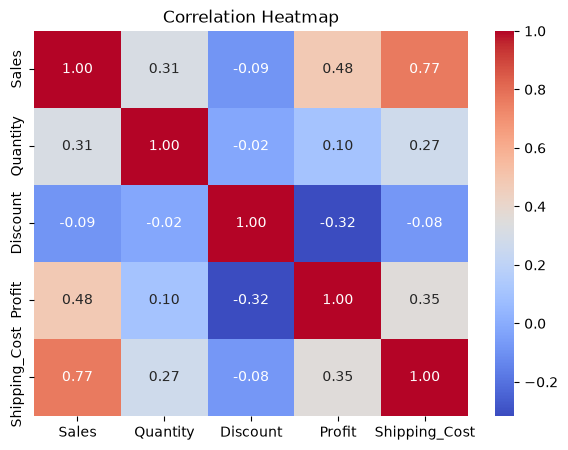

In [21]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[["Sales", "Quantity", "Discount", "Profit", "Shipping_Cost"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

# Export the cleaned file

In [23]:
df.to_csv(r"C:\Users\SANJAY\Documents\data\superstore_clean.csv", index=False)
print("Saved:", df.shape)

Saved: (51290, 30)
